# 04 — Demonstração de detecções e mensagens em texto

Este notebook é uma demonstração qualitativa do detector e das regras históricas.
As imagens de exemplo são escolhidas automaticamente. Os CSVs são saídas prontas.
Não há preenchimento manual nem geração de áudio.

As regras foram extraídas da V2 original e centralizadas em `src/politica_alertas.py`.
Para avaliação de todas as imagens, com detecções extras e objetos não detectados,
use o notebook 05d. Os exemplos deste notebook não medem acurácia de risco físico.


## 1. Antes de executar

Baixe o arquivo `best.pt` que foi salvo no Google Drive durante o treinamento.

Coloque-o nesta pasta do projeto:

```text
tcc_visao_computacional/
└── models/
    └── yolov8n_baseline/
        └── best.pt
```

O dataset processado criado no notebook 02 deverá continuar em:

```text
data/processed/homeobjects_yolo/
```

## 2. Importações e localização da raiz do projeto

In [1]:
from pathlib import Path
from datetime import datetime
import random
import sys

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image, ImageDraw, ImageFont


def localizar_raiz_projeto() -> Path:
    atual = Path.cwd().resolve()

    for candidata in [atual, *atual.parents]:
        if (
            (candidata / "src/politica_alertas.py").is_file()
        ):
            return candidata

    raise FileNotFoundError(
        "Não foi possível localizar a raiz do projeto."
    )


RAIZ_PROJETO = localizar_raiz_projeto()

if str(RAIZ_PROJETO) not in sys.path:
    sys.path.insert(0, str(RAIZ_PROJETO))

print("Raiz do projeto:", RAIZ_PROJETO)


Raiz do projeto: C:\Users\diego\OneDrive\Documentos_One_Drive\TCC\tcc_visao_computacional


## 3. Instalar/importar Ultralytics

Se a biblioteca já estiver instalada no ambiente virtual, esta célula apenas fará a importação.

In [2]:
try:
    from ultralytics import YOLO
except ImportError:
    import subprocess

    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "ultralytics"]
    )

    from ultralytics import YOLO

print("Ultralytics importado com sucesso.")

Ultralytics importado com sucesso.


## 4. Caminhos do projeto

In [3]:
CAMINHO_MODELO = RAIZ_PROJETO / "models/yolov8n_retreino_01/best.pt"
PASTA_TEST = RAIZ_PROJETO / "data/processed/homeobjects_yolo/images/test"
IDENTIFICADOR = datetime.now().strftime('%Y%m%d_%H%M%S_%f')
PASTA_EXECUCAO = RAIZ_PROJETO / 'reports/demonstracao_risco' / 'v1' / IDENTIFICADOR
PASTA_RESULTADOS = PASTA_EXECUCAO / 'imagens'
PASTA_TABELAS = PASTA_EXECUCAO / 'tabelas'
if not CAMINHO_MODELO.is_file():
    raise FileNotFoundError(f'Modelo não encontrado: {CAMINHO_MODELO}')
if not PASTA_TEST.is_dir():
    raise FileNotFoundError(f'TEST não encontrado: {PASTA_TEST}')
PASTA_RESULTADOS.mkdir(parents=True, exist_ok=False)
PASTA_TABELAS.mkdir(parents=True, exist_ok=False)
print('Modelo:', CAMINHO_MODELO)
print('Resultados desta demonstração:', PASTA_EXECUCAO)


Modelo: C:\Users\diego\OneDrive\Documentos_One_Drive\TCC\tcc_visao_computacional\models\yolov8n_retreino_01\best.pt
Resultados desta demonstração: C:\Users\diego\OneDrive\Documentos_One_Drive\TCC\tcc_visao_computacional\reports\demonstracao_risco\v1\20261013_014110_195583


# 5. Definição das regras de risco

Vamos separar as 12 classes em três grupos.

### Objetos avaliados como possíveis obstáculos físicos

- `bed`
- `sofa`
- `chair`
- `table`
- `wardrobe`
- `potted plant`

### Objetos contextuais

- `lamp`
- `door`

Eles podem ou não representar um obstáculo dependendo da situação.
O dataset não informa, por exemplo, se uma porta está aberta ou fechada
ou se uma luminária está no chão ou sobre uma mesa.

### Objetos ignorados na avaliação de locomoção

- `tv`
- `laptop`
- `window`
- `photo frame`

O YOLO continua detectando essas classes, mas elas não recebem
classificação automática de risco nesta primeira versão.

In [4]:
from src.politica_alertas import (
    PESO_OBJETO, CLASSES_CONTEXTUAIS, CLASSES_IGNORADAS,
    LIMITE_ESQUERDA, LIMITE_DIREITA, LIMITE_AREA_MEDIA, LIMITE_AREA_GRANDE,
    LIMITE_VERTICAL_SUPERIOR, LIMITE_VERTICAL_INFERIOR,
    PESO_POSICAO, PESO_TAMANHO, AJUSTE_VERTICAL,
    classificar_posicao, classificar_tamanho, classificar_posicao_vertical,
    classificar_risco_v1, classificar_risco_v2, gerar_mensagens_tabela,
)

classificar_risco = classificar_risco_v1


## Regras espaciais fixas

O centro horizontal da caixa define a posição em três terços da largura:

| Região | Centro horizontal normalizado |
|---|---|
| Esquerda | menor que 1/3 |
| Centro | de 1/3 até menos de 2/3 |
| Direita | 2/3 ou mais |

A área da caixa dividida pela área da imagem define o tamanho:
pequeno abaixo de 5%, médio de 5% até menos de 20%, grande a partir de 20%.
Na V2, a base inferior da caixa define a região vertical: superior abaixo de 60%,
intermediária de 60% até menos de 80%, inferior a partir de 80% da altura.
A V1 ignora esse ajuste vertical. Os parâmetros reproduzem a política histórica
e não são ajustados a partir dos resultados do TEST.


In [5]:
# Limiares importados da política original; não reestimados com o TEST.


## 7. Funções de avaliação

A pontuação será calculada somente para classes tratadas como possíveis obstáculos:

```text
pontuação =
    peso do objeto
    + peso da posição
    + peso do tamanho
```

Classificação inicial:

```text
3–4  → baixo
5–6  → médio
7–9  → alto
```

As classes contextuais recebem o status `contextual`.
As classes sem relevância para locomoção recebem `ignorado`.

In [6]:
# Funções e constantes importadas da política histórica.


## 8. Carregar o modelo treinado

In [7]:
modelo = YOLO(str(CAMINHO_MODELO))

print("Modelo carregado.")
print("Classes:")
print(modelo.names)

Modelo carregado.
Classes:
{0: 'bed', 1: 'sofa', 2: 'chair', 3: 'table', 4: 'lamp', 5: 'tv', 6: 'laptop', 7: 'wardrobe', 8: 'window', 9: 'door', 10: 'potted plant', 11: 'photo frame'}


# 9. Função principal de análise de uma imagem

Esta função:

1. executa o YOLO;
2. extrai cada bounding box;
3. calcula posição;
4. calcula ocupação da imagem;
5. atribui a classificação de risco;
6. retorna uma tabela com todos os objetos detectados.

In [8]:
def analisar_imagem(
    caminho_imagem,
    confianca_minima=0.25,
):
    caminho_imagem = Path(caminho_imagem)

    imagem = Image.open(caminho_imagem).convert("RGB")
    largura, altura = imagem.size
    area_imagem = largura * altura

    resultados = modelo.predict(
        source=str(caminho_imagem),
        conf=confianca_minima,
        verbose=False,
    )

    resultado = resultados[0]
    registros = []

    if resultado.boxes is None:
        return pd.DataFrame(), imagem

    for box in resultado.boxes:
        classe_id = int(box.cls[0].item())
        classe = modelo.names[classe_id]
        confianca = float(box.conf[0].item())

        x1, y1, x2, y2 = [
            float(valor)
            for valor in box.xyxy[0].tolist()
        ]

        largura_box = x2 - x1
        altura_box = y2 - y1
        area_box = largura_box * altura_box

        centro_x = (x1 + x2) / 2

        posicao = classificar_posicao(
            centro_x=centro_x,
            largura_imagem=largura,
        )

        tamanho, proporcao_area = classificar_tamanho(
            area_box=area_box,
            area_imagem=area_imagem,
        )

        avaliacao = classificar_risco(
            classe=classe,
            posicao=posicao,
            tamanho=tamanho,
        )

        registros.append(
            {
                "arquivo": caminho_imagem.name,
                "classe": classe,
                "confianca": confianca,
                "x1": x1,
                "y1": y1,
                "x2": x2,
                "y2": y2,
                "posicao": posicao,
                "ocupacao_imagem": proporcao_area,
                "tamanho": tamanho,
                "pontuacao": avaliacao["pontuacao"],
                "nivel_risco": avaliacao["nivel_risco"],
                "motivo": avaliacao["motivo"],
            }
        )

    return pd.DataFrame(registros), imagem

## 10. Selecionar uma imagem de teste

Inicialmente utilizaremos uma imagem aleatória do conjunto TEST.

A semente fixa garante que o mesmo exemplo seja selecionado ao executar novamente o notebook.

In [9]:
EXTENSOES_IMAGEM = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

imagens_test = sorted(
    arquivo
    for arquivo in PASTA_TEST.rglob("*")
    if arquivo.is_file()
    and arquivo.suffix.lower() in EXTENSOES_IMAGEM
)

if not imagens_test:
    raise RuntimeError("Nenhuma imagem encontrada no conjunto TEST.")

random.seed(42)
imagem_teste = random.choice(imagens_test)

print("Imagem selecionada:")
print(imagem_teste)

Imagem selecionada:
C:\Users\diego\OneDrive\Documentos_One_Drive\TCC\tcc_visao_computacional\data\processed\homeobjects_yolo\images\test\living_room_712.jpg


## 11. Executar a avaliação

In [10]:
df_deteccoes, imagem_original = analisar_imagem(
    imagem_teste,
    confianca_minima=0.25,
)

colunas_exibicao = [
    "classe",
    "confianca",
    "posicao",
    "ocupacao_imagem",
    "tamanho",
    "pontuacao",
    "nivel_risco",
]

if df_deteccoes.empty:
    print("Nenhum objeto detectado.")
else:
    display(
        df_deteccoes[colunas_exibicao]
        .sort_values(
            ["nivel_risco", "confianca"],
            ascending=[True, False],
        )
    )

,classe,confianca,posicao,ocupacao_imagem,tamanho,pontuacao,nivel_risco
1,potted plant,0.838002,centro,0.082502,medio,7.0,alto
2,table,0.725217,centro,0.374915,grande,9.0,alto
8,wardrobe,0.252361,centro,0.390398,grande,9.0,alto
4,potted plant,0.599235,direita,0.004090,pequeno,4.0,baixo
3,door,0.647616,esquerda,0.062751,medio,NaN,contextual
7,door,0.284415,esquerda,0.030490,pequeno,NaN,contextual
6,photo frame,0.289952,centro,0.008201,pequeno,0.0,ignorado
0,wardrobe,0.840585,direita,0.086570,medio,6.0,medio
5,chair,0.294970,esquerda,0.124463,medio,6.0,medio


# 12. Visualizar as detecções e o nível de risco

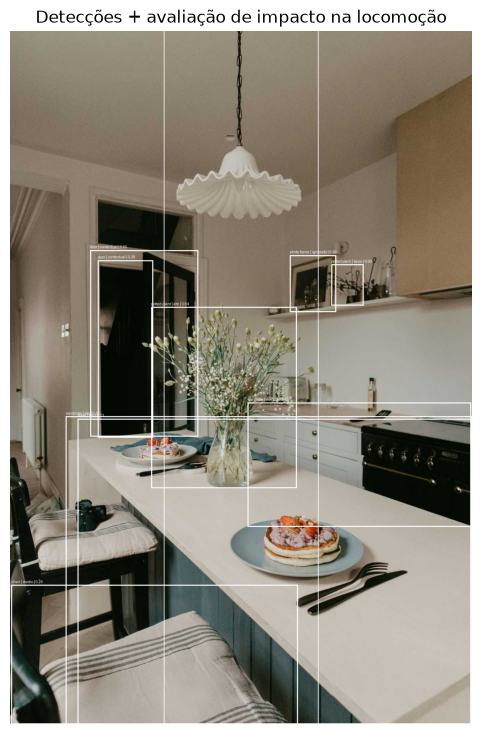

In [11]:
def desenhar_resultados(
    imagem,
    df,
):
    imagem_saida = imagem.copy()
    desenho = ImageDraw.Draw(imagem_saida)

    largura, altura = imagem_saida.size

    # Linhas que representam as três regiões horizontais.
    x_esquerda = int(largura * LIMITE_ESQUERDA)
    x_direita = int(largura * LIMITE_DIREITA)

    desenho.line(
        [(x_esquerda, 0), (x_esquerda, altura)],
        width=2,
    )
    desenho.line(
        [(x_direita, 0), (x_direita, altura)],
        width=2,
    )

    for _, linha in df.iterrows():
        caixa = (
            linha["x1"],
            linha["y1"],
            linha["x2"],
            linha["y2"],
        )

        desenho.rectangle(
            caixa,
            width=3,
        )

        texto = (
            f'{linha["classe"]} | '
            f'{linha["nivel_risco"]} | '
            f'{linha["confianca"]:.2f}'
        )

        desenho.text(
            (linha["x1"], max(linha["y1"] - 15, 0)),
            texto,
        )

    return imagem_saida


imagem_anotada = desenhar_resultados(
    imagem_original,
    df_deteccoes,
)

plt.figure(figsize=(14, 9))
plt.imshow(imagem_anotada)
plt.axis("off")
plt.title("Detecções + avaliação de impacto na locomoção")
plt.show()

## 13. Mensagens automáticas em texto

As mensagens são emitidas somente quando a política aciona um alerta.


In [12]:
def gerar_mensagens(df):
    return gerar_mensagens_tabela(df, coluna='nivel_risco')
mensagens = gerar_mensagens(df_deteccoes)
for mensagem in mensagens:
    print(mensagem)


Atenção: guarda-roupa detectado na região central da imagem. Prioridade alta.
Atenção: mesa detectada na região central da imagem. Prioridade alta.
Atenção: planta em vaso detectada na região central da imagem. Prioridade alta.
Atenção: cadeira detectada na região esquerda da imagem. Prioridade média.
Atenção: guarda-roupa detectado na região direita da imagem. Prioridade média.


# 14. Testar várias imagens

Uma única imagem não é suficiente para validar a regra.

Vamos selecionar **20 imagens aleatórias** do conjunto TEST e registrar todas as detecções e avaliações.

In [13]:
random.seed(42)

quantidade_amostras = min(20, len(imagens_test))
amostras = random.sample(
    imagens_test,
    quantidade_amostras,
)

resultados_amostras = []

for indice, caminho_imagem in enumerate(amostras, start=1):
    print(
        f"[{indice:02d}/{quantidade_amostras}] "
        f"{caminho_imagem.name}"
    )

    df_imagem, _ = analisar_imagem(
        caminho_imagem,
        confianca_minima=0.25,
    )

    if not df_imagem.empty:
        resultados_amostras.append(df_imagem)

if resultados_amostras:
    df_amostras = pd.concat(
        resultados_amostras,
        ignore_index=True,
    )
else:
    df_amostras = pd.DataFrame()

print()
print("Detecções analisadas:", len(df_amostras))

[01/20] living_room_712.jpg
[02/20] living_room_1p (118).jpg
[03/20] living_room_1040.jpg
[04/20] living_room_908.jpg
[05/20] living_room_1p (439).jpg
[06/20] living_room_1p (382).jpg
[07/20] living_room_1p (339).jpg
[08/20] living_room_1p (173).jpg
[09/20] living_room_900.jpg
[10/20] living_room_1p (10).jpg
[11/20] living_room_780.jpg
[12/20] living_room_538.jpg
[13/20] living_room_168.jpg
[14/20] living_room_62.jpg
[15/20] living_room_303.jpg
[16/20] living_room_1059.jpg
[17/20] living_room_1055.jpg
[18/20] living_room_180.jpg
[19/20] living_room_1p (326).jpg
[20/20] living_room_1p (357).jpg

Detecções analisadas: 208


## 15. Resumo dos níveis produzidos

Essa tabela não mede ainda se a classificação de risco está correta.

Ela serve para entendermos **como nossa regra está se comportando**.

In [14]:
if not df_amostras.empty:
    resumo_risco = (
        df_amostras
        .groupby(
            ["nivel_risco", "classe"],
            dropna=False,
        )
        .size()
        .reset_index(name="quantidade")
        .sort_values(
            ["nivel_risco", "quantidade"],
            ascending=[True, False],
        )
    )

    display(resumo_risco)

,nivel_risco,classe,quantidade
3,alto,sofa,11
4,alto,table,10
2,alto,potted plant,5
1,alto,chair,3
5,alto,wardrobe,3
0,alto,bed,2
6,baixo,potted plant,31
8,contextual,lamp,16
7,contextual,door,6
9,ignorado,photo frame,29


## 16. Salvar resultados da primeira avaliação

In [15]:
if not df_amostras.empty:
    caminho_csv = (
        PASTA_TABELAS
        / "avaliacao_risco_amostras.csv"
    )

    df_amostras.to_csv(
        caminho_csv,
        index=False,
        encoding="utf-8-sig",
    )

    print("Arquivo salvo em:")
    print(caminho_csv)

caminho_imagem_saida = (
    PASTA_RESULTADOS
    / "exemplo_avaliacao_risco.jpg"
)

imagem_anotada.save(caminho_imagem_saida)

print()
print("Imagem salva em:")
print(caminho_imagem_saida)

Arquivo salvo em:
C:\Users\diego\OneDrive\Documentos_One_Drive\TCC\tcc_visao_computacional\reports\demonstracao_risco\v1\20261013_014110_195583\tabelas\avaliacao_risco_amostras.csv

Imagem salva em:
C:\Users\diego\OneDrive\Documentos_One_Drive\TCC\tcc_visao_computacional\reports\demonstracao_risco\v1\20261013_014110_195583\imagens\exemplo_avaliacao_risco.jpg


## 17. Papel desta demonstração

A V1 fica como regra histórica de comparação. A aplicação atual utiliza a V2, com saída em texto. Este notebook descreve detecções e pontuações em uma amostra; a avaliação de todas as imagens e dos erros do detector é feita no 05d. A referência automática da política não comprova risco físico independentemente.


## Próxima etapa

Use o 05d para avaliação automática de todas as imagens. A V1 fica como referência histórica; não requer cenários preenchidos manualmente.
